In [1]:
import pandas as pd

df = pd.read_csv("d/de.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 7043
Columns: 21


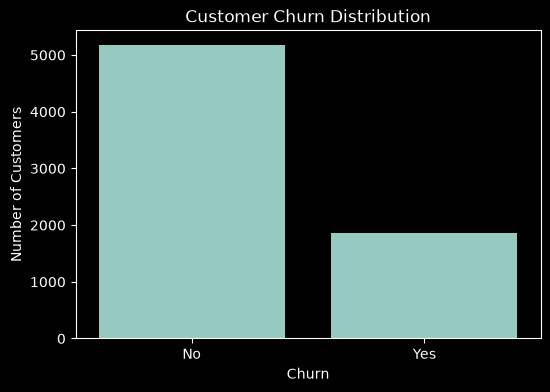

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [6]:
print(df['Contract'].value_counts())

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [13]:
Contract_churn=pd.crosstab(df['Contract'], df['Churn'],normalize="index")*100
print(Contract_chrun)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


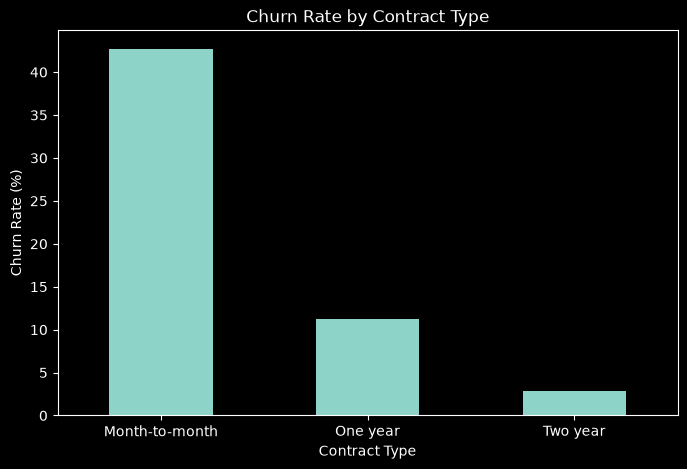

In [15]:
Contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [23]:

bins = [0, 6, 12, 24, 48, 72]
labels = [
    "0-6 months",
    "7-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
print(df["TenureGroup"].value_counts().sort_index())

TenureGroup
0-6 months      1481
7-12 months      705
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


In [24]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn)

Churn                No        Yes
TenureGroup                       
0-6 months    47.062795  52.937205
7-12 months   64.113475  35.886525
13-24 months  71.289062  28.710938
25-48 months  79.611041  20.388959
49-72 months  90.486824   9.513176


In [25]:
print(tenure_churn["Yes"])

TenureGroup
0-6 months      52.937205
7-12 months     35.886525
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Yes, dtype: float64


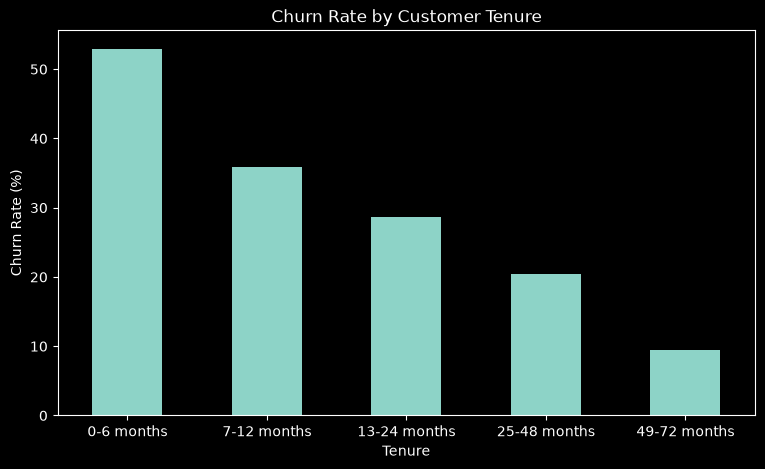

In [26]:
plt.figure(figsize=(9, 5))

tenure_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [29]:
print(df.groupby("Churn")["MonthlyCharges"].describe())

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


In [30]:
bins = [0, 30, 60, 90, 120, 150]

labels = [
    "₹0-30",
    "₹31-60",
    "₹61-90",
    "₹91-120",
    "₹121-150"
]

df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [31]:
charge_churn = pd.crosstab(
    df["MonthlyChargeGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(charge_churn)

Churn                      No        Yes
MonthlyChargeGroup                      
₹0-30               90.199637   9.800363
₹31-60              74.071146  25.928854
₹61-90              66.093881  33.906119
₹91-120             67.222542  32.777458


In [32]:
print(charge_churn["Yes"])

MonthlyChargeGroup
₹0-30       9.800363
₹31-60     25.928854
₹61-90     33.906119
₹91-120    32.777458
Name: Yes, dtype: float64


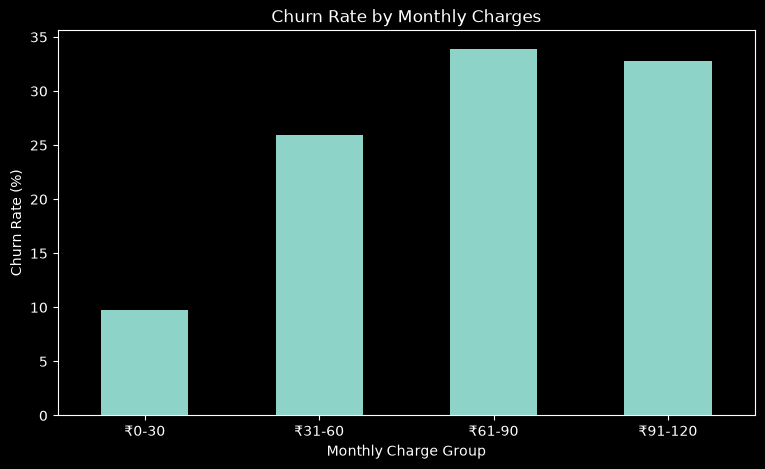

In [33]:
plt.figure(figsize=(9, 5))

charge_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [34]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100
print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


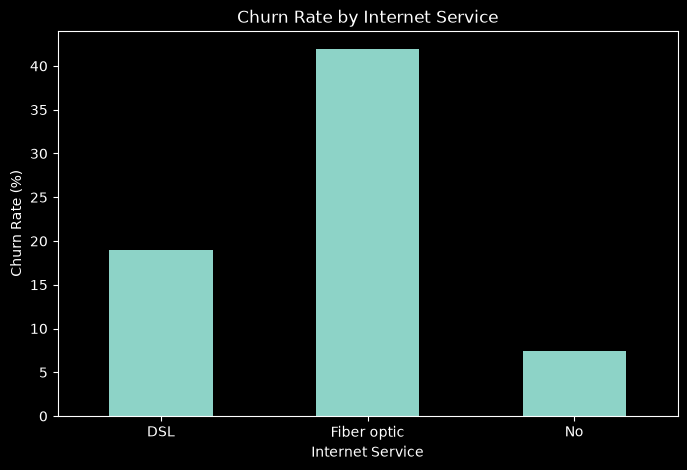

In [35]:
internet_churn["Yes"].plot(kind="bar", figsize=(8,5))

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [36]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(support_churn)

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


In [37]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


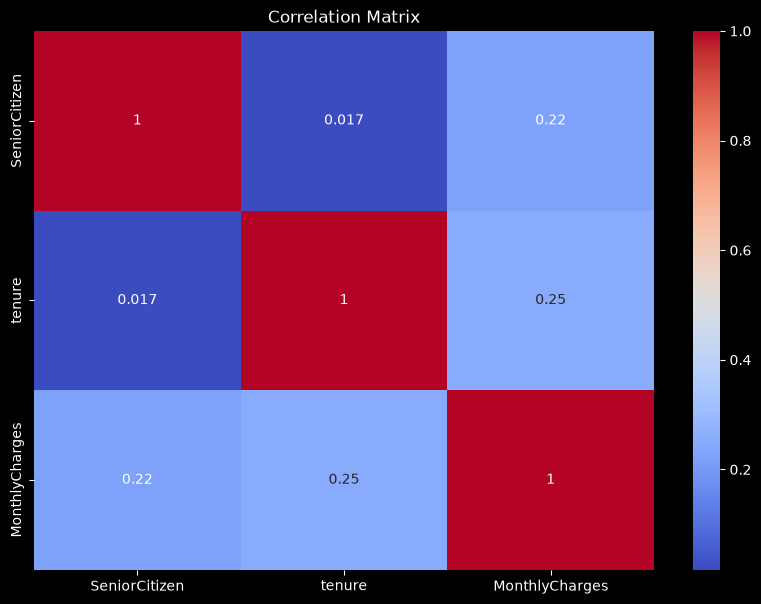

In [38]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()